In [2]:
using QuantumOptics, Plots, LinearAlgebra

# Task 1
 -g = 2κ = 6γ for different pump strengths R and atom numbers
 
 -Plot the average photon number ¯n =< a†a > and its standard deviation as well as the population difference σz
  between the two atomic states.

In [3]:
## setup  ##
nf = 16; #cutoff fock space
g = 1; # coupling
ħ = 1; 
δ = 0; # detuning: ωₐ-ω
ω = 0;

nt = 128;  tf = 12 ; T = LinRange(0,tf,nt); # time

basis_fock = FockBasis(nf);
basis_atom = SpinBasis(1//2);

basis_jc = basis_fock ⊗ basis_atom;

a = destroy(basis_fock) ⊗ one(basis_atom);
a⁺ = dagger(a);
n = a⁺*a;

σ = one(basis_fock) ⊗ sigmam(basis_atom);
σ⁺ = dagger(σ);
σᶻ = one(basis_fock)⊗sigmaz(basis_atom);

H = ħ*ω* a⁺*a + ħ*(ω + δ)*σ⁺*σ +  ħ*g*(a*σ⁺ + a⁺*σ);
K = g/2; # dampening via decay of field mode through cavity mirrors
γ=g/6; # atomic spontanious emission rate

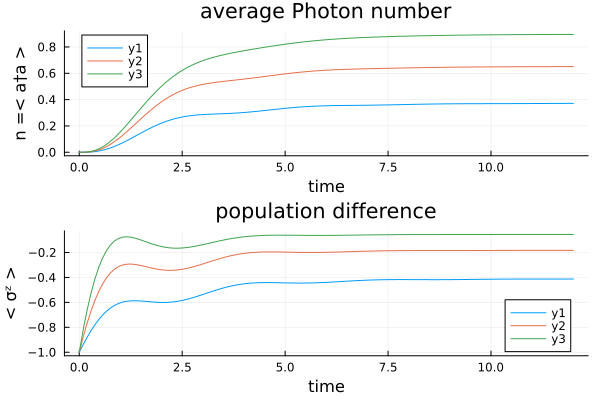

In [4]:
Rv=γ*[2, 4, 6]; # inverse spontaneous emission or "pumping"
ρ0 = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # densitymatrix of basis state |n=0, g>

Jr(R) = [sqrt(K)*a, sqrt(γ)*σ, sqrt(R)*σ⁺]; # decay operator

t1, ρ1t = timeevolution.master(T, ρ0, H, Jr(Rv[1]));
t2, ρ2t = timeevolution.master(T, ρ0, H, Jr(Rv[2]));
t3, ρ3t = timeevolution.master(T, ρ0, H, Jr(Rv[3]));

plt_1 = plot(title = "average Photon number", xlabel="time", ylabel="n =< a†a >");
plt_1 = plot!(t1, real.(expect(a⁺*a, ρ1t))); plt_1 = plot!(t2, real.(expect(a⁺*a, ρ2t))); plt_1 = plot!(t3, real.(expect(a⁺*a, ρ3t)));

plt_2 = plot(title = "population difference", xlabel="time", ylabel="< σᶻ >");
plt_2 = plot!(t1, real.(expect(σᶻ, ρ1t))); plt_2 = plot!(t2, real.(expect(σᶻ, ρ2t))); plt_2 = plot!(t3, real.(expect(σᶻ, ρ3t)));

plot(plt_1, plt_2, layout=(2,1))

# Task 2
-Generate a graph showing the the atomic population difference σz and photon number n in the staionary long
time limit

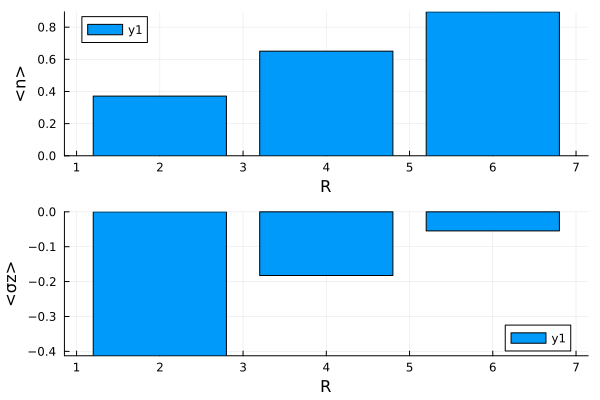

In [5]:
#long term limit
ρ1_end = ρ1t[end];
ρ2_end = ρ2t[end];
ρ3_end = ρ3t[end];

#photon number for each R#
ρ1_cav = ptrace(ρ1_end, 2); # we eliminate the atomic components of the density matrix and only take the cavity components. the entrys on the diagonal correspond to the photon number 
ρ2_cav = ptrace(ρ2_end, 2);
ρ3_cav = ptrace(ρ3_end, 2);

a_cav = destroy(basis_fock); # to treat these sub matrixes we need the operators for the according sub spaces. so in that case for just the fock space
a_cav⁺ = dagger(a_cav);
n_cav = a_cav⁺*a_cav;

pn_v = [];

pn_1 = expect(n_cav, ρ1_cav); append!(pn_v, [real.(pn_1)]);
pn_2 = expect(n_cav, ρ2_cav); append!(pn_v, [real.(pn_2)]);
pn_3 = expect(n_cav, ρ3_cav); append!(pn_v, [real.(pn_3)]);

#plot the photon number#
pn_ρ_end = plot(xlabel="R", ylabel="<n>");

pn_ρ_end = bar!([2,4,6], pn_v);

# <σz> for each R when σz = ∣e⟩⟨e∣ − ∣g⟩⟨g∣ #
ρ1_atm = ptrace(ρ1_end, 1); # we eliminate the cavity components of the density matrix 
ρ2_atm = ptrace(ρ2_end, 1);
ρ3_atm = ptrace(ρ3_end, 1);

σz_atm = sigmaz(basis_atom);

sigmaz_v = [];

p_sigmaz_1 = expect(σz_atm, ρ1_atm); append!(sigmaz_v, [real.(p_sigmaz_1)]);
p_sigmaz_2 = expect(σz_atm, ρ2_atm); append!(sigmaz_v, [real.(p_sigmaz_2)]);
p_sigmaz_3 = expect(σz_atm, ρ3_atm); append!(sigmaz_v, [real.(p_sigmaz_3)]);

pl_sigmaz = plot(xlabel="R", ylabel="<σz>");
pl_sigmaz = bar!([2,4,6], sigmaz_v);

plot(pn_ρ_end, pl_sigmaz, layout=(2,1))

# task 3
Plot the photon number distribution for weak R < γ, intermediate R ≈ γ and strong pump R > γ in the
stationary limit.

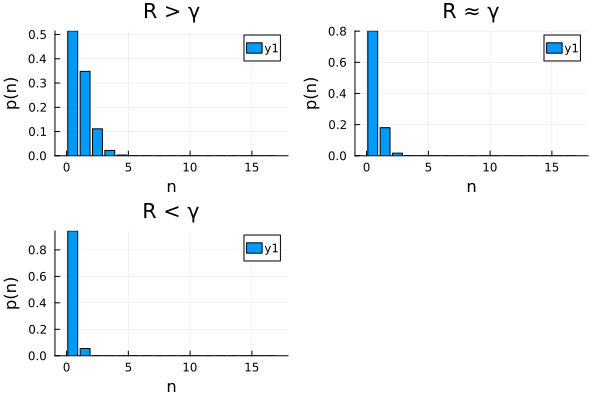

In [6]:
g=1; K=g/2; γ=g/6;

Rv = [γ/4, γ+0.01, 4*γ]; 

N = 0:1:17;
L = ["R < γ", "R ≈ γ", " R > γ "]

ρ0 = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # densitymatrix of basis state |n=0, g>

pl_n_v = [];

for i in 1:1:3
    t, ρt = timeevolution.master(T, ρ0, H, Jr(Rv[i]));
    ρ0_cav = ptrace(ρt[end], 2);
    p_n=real.(diag(ρ0_cav.data));
    l = L[i];
    push!(pl_n_v, bar(N, p_n, xlabel="n", ylabel="p(n)",title="$l"));
end

plot(pl_n_v[3], pl_n_v[2], pl_n_v[1])

# task 4
Compare the result with the solution based on a QMCWF-simulation
approach for single trajectories and averaging over many quantum stochastic trajectories

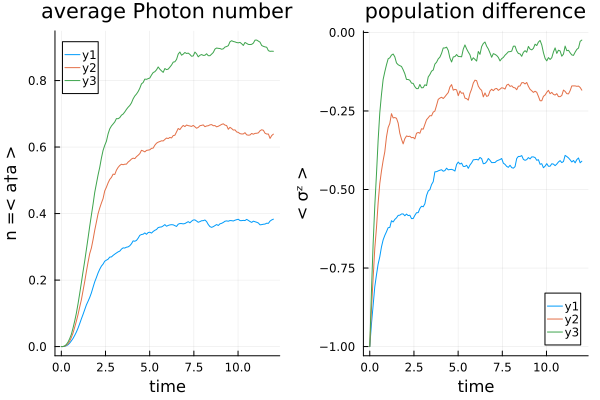

In [7]:
# comparing task 1 to monte carlo wafe funktion methode #
g=1;
K = g/2; # dampening via decay of field mode through cavity mirrors
γ=g/6; # atomic spontanious emission rate
Rv=γ*[2, 4, 6]; # inverse spontaneous emission or "pumping"
ψ0 = basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2); # densitymatrix of basis state |n=0, g>

Jr(R) = [sqrt(K)*a, sqrt(γ)*σ, sqrt(R)*σ⁺]; # decay operator

ntraj = 1700;

#create n single trajectorys 

n_avg1 = zeros(size(T));
pop_avg1 = zeros(size(T));

for k = 1:ntraj
    t, ψ0t = timeevolution.mcwf(T, ψ0, H, Jr(Rv[1]));
    n_avg1 += real.(expect(n, ψ0t));
    pop_avg1 += real.(expect(σᶻ, ψ0t));
end

n_avg2 = zeros(size(T));
pop_avg2 = zeros(size(T));

for k = 1:ntraj
    t, ψ0t = timeevolution.mcwf(T, ψ0, H, Jr(Rv[2]));
    n_avg2 += real.(expect(n, ψ0t));
    pop_avg2 += real.(expect(σᶻ, ψ0t));
end

n_avg3 = zeros(size(T));
pop_avg3 = zeros(size(T));

for k = 1:ntraj
    t, ψ0t = timeevolution.mcwf(T, ψ0, H, Jr(Rv[3]));
    n_avg3 += real.(expect(n, ψ0t));
    pop_avg3 += real.(expect(σᶻ, ψ0t));
end

n_plot = plot(title = "average Photon number", xlabel="time", ylabel="n =< a†a >");
n_plot = plot!(T, n_avg1/ntraj); n_plot = plot!(T, n_avg2/ntraj); n_plot = plot!(T, n_avg3/ntraj);

pop_plot = plot(title = "population difference", xlabel="time", ylabel="< σᶻ >");
pop_plot = plot!(T, pop_avg1/ntraj); pop_plot = plot!(T, pop_avg2/ntraj); pop_plot = plot!(T, pop_avg3/ntraj);

plot(n_plot, pop_plot, layot=(2,1))

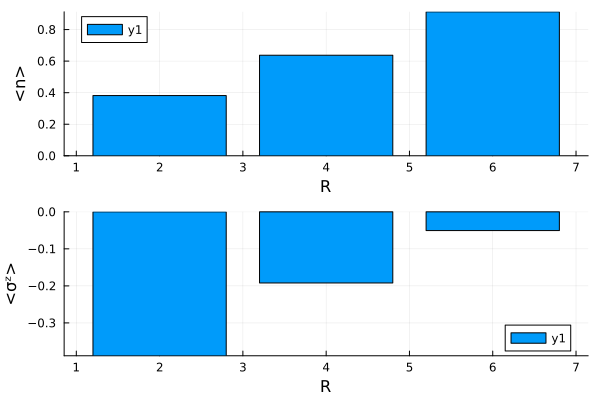

In [8]:
#comparing task 2 to mcwf methode#
n_sum = 0;
pop_sum = 0;

nvec = [];
popvec = [];

for i in Rv
    for k = 1:ntraj
        t, ψ0t = timeevolution.mcwf(T, ψ0, H, Jr(i));
        n_sum += real.(expect(n, ψ0t[end]));
        pop_sum += real.(expect(σᶻ, ψ0t[end]));
    end
    append!(nvec, n_sum/ntraj);
    n_sum = 0;

    append!(popvec, pop_sum/ntraj);
    pop_sum = 0;
end

n_plot = bar(title="", xlabel="R", ylabel="<n>");
n_plot = bar!([2,4,6], nvec);

pop_plot= bar(title="", xlabel="R", ylabel="<σᶻ>");
pop_plot = bar!([2,4,6], popvec);

plot(n_plot, pop_plot, layout=(2,1))

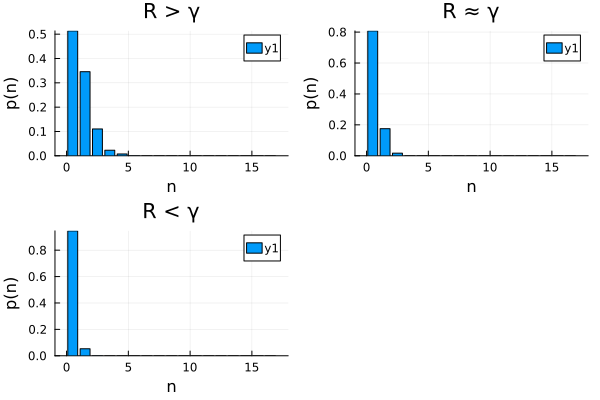

In [9]:
#comparing task 3 to mcwf methode#
g=1; K=g/2; γ=g/6;

Rv = [γ/4, γ+0.01, 4*γ];

N = 0:1:17;
L = ["R < γ", "R ≈ γ", " R > γ "]

pl_n_v = [];
rsum = nothing;

for i in 1:1:3
    for k in 1:ntraj
        t1, ψt1 = timeevolution.mcwf(T, ψ0, H, Jr(Rv[i]));
        ψ01_cav = ptrace(dm(ψt1[end]), 2);

        if k == 1
            rsum = ψ01_cav;
        else
            rsum += ψ01_cav;
        end
    end

    p_navg = rsum/ntraj;
    Pn = real.(diag(p_navg.data));
    l = L[i];
    push!(pl_n_v, bar(N, Pn, xlabel="n", ylabel="p(n)",title="$l"));
end

plot(pl_n_v[3], pl_n_v[2], pl_n_v[1])

## Task 5
Calculate the field phase space distribution (Husimi function = qfunc() ) based on
the first approach for the two cases of weak and strong pumping.

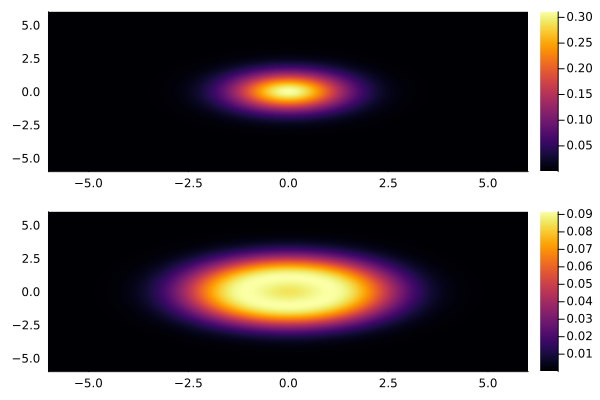

In [10]:
Rv = [γ/10, γ*10];
Jr(R) = [sqrt(K)*a, sqrt(γ)*σ, sqrt(R)*σ⁺];
points = -6:0.01:6;

ρ0 = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); 

tw, ρ0tw = timeevolution.master(T, ρ0, H, Jr(Rv[1]));
ts, ρ0ts = timeevolution.master(T, ρ0, H, Jr(Rv[2]));

ρ0tw_cav = ptrace(ρ0tw[end], 2);
ρ0ts_cav = ptrace(ρ0ts[end], 2);

q_ρw = qfunc(ρ0tw_cav, points, points);
q_ρs = qfunc(ρ0ts_cav, points, points);

hm_w = heatmap(points, points, real(q_ρw));
hm_s = heatmap(points, points, real(q_ρs));

plot(hm_w, hm_s, layout=(2,1))

## Task 6
Output spectra: Calculate the laser output spectrum via two-time correlation functions for methods 1 and 3.

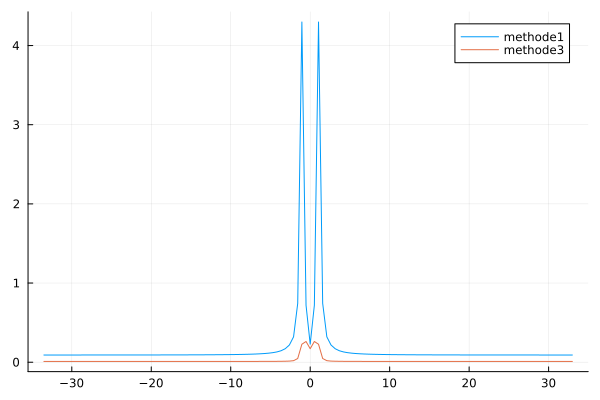

In [107]:
#methode 1#
Jr(R) = [sqrt(K)*a, sqrt(γ)*σ, sqrt(R)*σ⁺];
δ = 0;
ω = 1;
g = 1;
K = g/2; 
γ = g/6;
R = 0.5*γ;

ρ0 = dm(basisstate(basis_fock, 2)⊗basisstate(basis_atom, 2)); # densitymatrix of basis state |n=1, g>
corr_m1 = timecorrelations.correlation(T, ρ0, H, Jr(R), a⁺, a);
ω_m1, s_m1 = timecorrelations.correlation2spectrum(T, corr_m1);

rsum = nothing;
ntraj = 200;

for k in 1:ntraj
    t, ψ0t = timeevolution.mcwf(T, ψ0, H, Jr(R));
    ψ0t1 = dm(ψ0t[end]);
    if k == 1
        rsum = ψ0t1;
    else
        rsum += ψ0t1;
    end
    
end

avg = rsum/ntraj;

corr_m3 = timecorrelations.correlation(T, avg, H, Jr(2*γ), a⁺, a);
ω_m3, s_m3 = timecorrelations.correlation2spectrum(T, corr_m3);

spec_plot = plot( xlabel="", ylabel="", title="");
spec_plot = plot!(ω_m1, s_m1, label="methode1")
spec_plot = plot!(ω_m3, s_m3, label="methode3")